In [1]:
import os
import pandas as pd

DATASET_PATH = "dataset"

data = []

for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)

    if os.path.isdir(folder_path):
        for file in os.listdir(folder_path):

            if not file.lower().endswith(('.png', '.jpg', '.jpeg')):
                continue

            filepath = os.path.join(folder, file)

            label = {
                "filename": filepath,
                "acne_inflammatory": 0,
                "acne_noninflammatory": 0,
                "hyperpigmentation": 0,
                "wrinkles": 0
            }

            if folder == "acne_inflammatory":
                label["acne_inflammatory"] = 1
            elif folder == "acne_noninflammatory":
                label["acne_noninflammatory"] = 1
            elif folder == "hyperpigmentation":
                label["hyperpigmentation"] = 1
            elif folder == "wrinkles":
                label["wrinkles"] = 1

            data.append(label)

df = pd.DataFrame(data)

In [2]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

DATA AGUMENTATION


In [3]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

DATA GENERATOR

In [5]:
from tensorflow.keras.utils import Sequence
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
import math
import os

class DataGenerator(Sequence):

    def __init__(self, df, batch_size=32, augment=False):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.augment = augment
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.df) / self.batch_size)

    def __getitem__(self, index):
        batch_df = self.df.iloc[index*self.batch_size:(index+1)*self.batch_size]

        images, labels = [], []

        for i in range(len(batch_df)):
            img_path = os.path.join("dataset", batch_df.iloc[i]['filename'])

            img = load_img(img_path, target_size=(224,224))
            img = img_to_array(img)

            if self.augment:
                img = data_augmentation(img)

            img = preprocess_input(img)

            label = batch_df.iloc[i][[
                "acne_inflammatory",
                "acne_noninflammatory",
                "hyperpigmentation",
                "wrinkles"
            ]].values.astype(float)

            images.append(img)
            labels.append(label)

        return np.array(images), np.array(labels)

    def on_epoch_end(self):
        self.df = self.df.sample(frac=1).reset_index(drop=True)

GENERATORS

In [6]:
train_gen = DataGenerator(train_df, batch_size=32, augment=True)
val_gen = DataGenerator(val_df, batch_size=32, augment=False)

MODEL USING MobileNetV2

In [7]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

# Freeze all layers
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze only last 10 layers (REDUCED)
for layer in base_model.layers[-10:]:
    layer.trainable = True

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),   # reduced
    BatchNormalization(),
    Dropout(0.6),                    # increased

    Dense(64, activation='relu'),    # reduced
    BatchNormalization(),

    Dense(4, activation='sigmoid')
])

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.00001),   # reduced LR
    loss='binary_crossentropy',
    metrics=['accuracy','AUC', 'Precision', 'Recall']
)

In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

lr_reduce = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=2,
    min_lr=1e-6
)

In [10]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=25,
    callbacks=[early_stop, lr_reduce]
)

C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 306s 1s/step - AUC: 0.5904 - Precision: 0.2963 - Recall: 0.5962 - accuracy: 0.3424 - loss: 0.8152 - val_AUC: 0.7520 - val_Precision: 0.3561 - val_Recall: 0.8372 - val_accuracy: 0.5117 - val_loss: 0.7116 - learning_rate: 1.0000e-05
Epoch 2/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 291s 1s/step - AUC: 0.7393 - Precision: 0.3823 - Recall: 0.7427 - accuracy: 0.5318 - loss: 0.6804 - val_AUC: 0.8571 - val_Precision: 0.4303 - val_Recall: 0.8931 - val_accuracy: 0.6622 - val_loss: 0.6034 - learning_rate: 1.0000e-05
Epoch 3/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 390s 2s/step - AUC: 0.8117 - Precision: 0.4253 - Recall: 0.8048 - accuracy: 0.6267 - loss: 0.6122 - val_AUC: 0.8959 - val_Precision: 0.4712 - val_Recall: 0.9029 - val_accuracy: 0.7211 - val_loss: 0.5448 - learning_rate: 1.0000e-05
Epoch 4/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 408s 2s/step - AUC: 0.8544 - Precision: 0.4637 - Recall: 0.8535 - accuracy: 0.6823 - loss: 0.5644 - val_AUC: 0.9199 - val_Precision: 0.5105 - val_R

In [11]:
model.save("skin_condition_improvedmodel.h5")

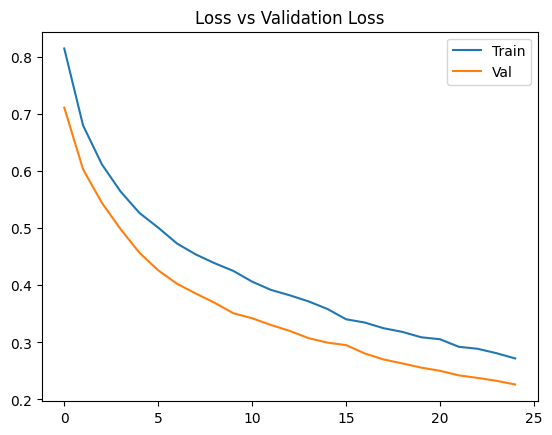

In [12]:
import matplotlib.pyplot as plt

# Loss
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss vs Validation Loss")
plt.legend(["Train", "Val"])
plt.show()

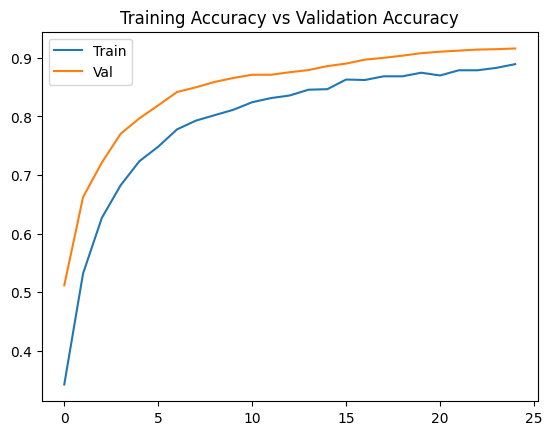

In [21]:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Training Accuracy vs Validation Accuracy")
plt.legend(["Train", "Val"])
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 944ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 746ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 916ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 724ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 641ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 621ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 720ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 715ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 775ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 824ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 744ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 768ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 911ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 874ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 672ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 749ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 863ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 820ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 680ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 637ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 638ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 627ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 696ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 655ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 

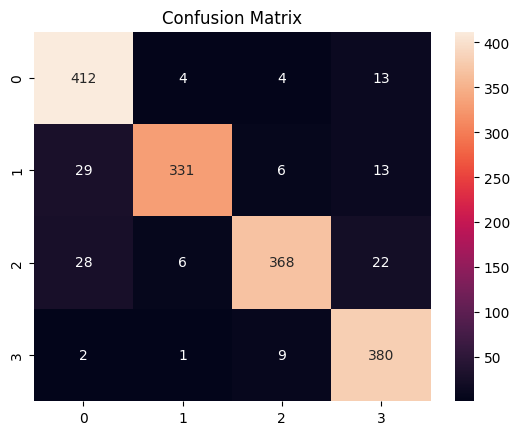

              precision    recall  f1-score   support

           0       0.87      0.95      0.91       433
           1       0.97      0.87      0.92       379
           2       0.95      0.87      0.91       424
           3       0.89      0.97      0.93       392

    accuracy                           0.92      1628
   macro avg       0.92      0.92      0.92      1628
weighted avg       0.92      0.92      0.92      1628



In [20]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_true, y_pred = [], []

for i in range(len(val_gen)):
    X, y = val_gen[i]
    preds = model.predict(X)

    y_true.extend(y)
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

y_true_class = np.argmax(y_true, axis=1)
y_pred_class = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_true_class, y_pred_class)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true_class, y_pred_class))

In [22]:
def predict_image(img_path):
    from tensorflow.keras.preprocessing.image import load_img, img_to_array
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
    import numpy as np

    img = load_img(img_path, target_size=(224,224))
    img = img_to_array(img)
    img = preprocess_input(img)
    img = np.expand_dims(img, axis=0)

    preds = model.predict(img)[0]

    classes = [
        "acne_inflammatory",
        "acne_noninflammatory",
        "hyperpigmentation",
        "wrinkles"
    ]

    for i, p in enumerate(preds):
        print(f"{classes[i]}: {p*100:.2f}%")

    print("Final Prediction:", classes[np.argmax(preds)])

In [2]:
import os

DATASET_PATH = "dataset"

for class_name in os.listdir(DATASET_PATH):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        count = len(os.listdir(class_path))
        print(f"{class_name}: {count} images")

acne_inflammatory: 2060 images
acne_noninflammatory: 1970 images
hyperpigmentation: 2126 images
normal skin: 0 images
wrinkles: 1982 images


In [6]:
import os

DATASET_PATH = "dataset"

total_images = 0

for class_name in os.listdir(DATASET_PATH):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        total_images += len(os.listdir(class_path))

print("Total Images:", total_images)

Total Images: 8138
